# Phase 4: Model Evaluation & Comparative Visualization
**Project:** California Housing Price Prediction  
**Models:** Random Forest  vs XGBoost   
**Data Preprocessing:** California Housing  
**Evaluation & Visualization:** 

---

## Cell 1 — Imports

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", palette="mako")
plt.rcParams["figure.dpi"] = 120

print("All imports loaded.")


All imports loaded.


## Cell 2 — Reproduce California Housing Data Preprocessing

In [37]:
rf_model  = joblib.load("random_forest_best_model.joblib")
xgb_model = joblib.load("models/xgboost_model.joblib")

X_test = pd.read_csv("X_test.csv")
y_test = pd.read_csv("y_test.csv").squeeze()

print(f"X_test shape : {X_test.shape}")
print(f"y_test shape : {y_test.shape}")
print("Data ready.")

X_test shape : (4128, 8)
y_test shape : (4128,)
Data ready.


## Cell 3 — Load Both Trained Models

In [38]:
rf_preds  = rf_model.predict(X_test)
xgb_preds = xgb_model.predict(X_test)

rf_residuals  = y_test.values - rf_preds
xgb_residuals = y_test.values - xgb_preds

print("Predictions generated.")
print(f"  RF  first 5: {rf_preds[:5].round(3)}")
print(f"  XGB first 5: {xgb_preds[:5].round(3)}")
print(f"  Actual  first 5: {y_test.values[:5].round(3)}")

Predictions generated.
  RF  first 5: [0.497 0.746 4.877 2.54  2.298]
  XGB first 5: [0.714 1.092 3.69  2.431 2.006]
  Actual  first 5: [0.477 0.458 5.    2.186 2.78 ]


## Cell 4 — Generate Predictions & Residuals

In [39]:
rf_preds  = rf_model.predict(X_test)
xgb_preds = xgb_model.predict(X_test)

rf_residuals  = y_test.values - rf_preds
xgb_residuals = y_test.values - xgb_preds

print("Predictions generated.")
print(f"  RF  first 5: {rf_preds[:5].round(3)}")
print(f"  XGB first 5: {xgb_preds[:5].round(3)}")
print(f"  Actual  first 5: {y_test.values[:5].round(3)}")


Predictions generated.
  RF  first 5: [0.497 0.746 4.877 2.54  2.298]
  XGB first 5: [0.714 1.092 3.69  2.431 2.006]
  Actual  first 5: [0.477 0.458 5.    2.186 2.78 ]


## Cell 5 — Metrics Comparison Table
> RMSE and MAE: lower is better. R²: higher is better (max = 1.0)


In [40]:
def get_metrics(y_true, y_pred, name):
    return {
        "Model" : name,
        "RMSE"  : round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "MAE"   : round(mean_absolute_error(y_true, y_pred), 4),
        "R2"    : round(r2_score(y_true, y_pred), 4),
    }

metrics = pd.DataFrame([
    get_metrics(y_test, rf_preds,  "Random Forest"),
    get_metrics(y_test, xgb_preds, "XGBoost"),
]).set_index("Model")

print("=" * 45)
print("     MODEL PERFORMANCE COMPARISON TABLE")
print("=" * 45)
print(metrics.to_string())
print("=" * 45)
print(f"  Best RMSE -> {metrics['RMSE'].idxmin()}")
print(f"  Best MAE  -> {metrics['MAE'].idxmin()}")
print(f"  Best R2   -> {metrics['R2'].idxmax()}")


     MODEL PERFORMANCE COMPARISON TABLE
                 RMSE     MAE      R2
Model                                
Random Forest  0.5041  0.3265  0.8061
XGBoost        0.5829  0.4086  0.7407
  Best RMSE -> Random Forest
  Best MAE  -> Random Forest
  Best R2   -> Random Forest


## Cell 6 — Visualization 1: Metrics Bar Chart

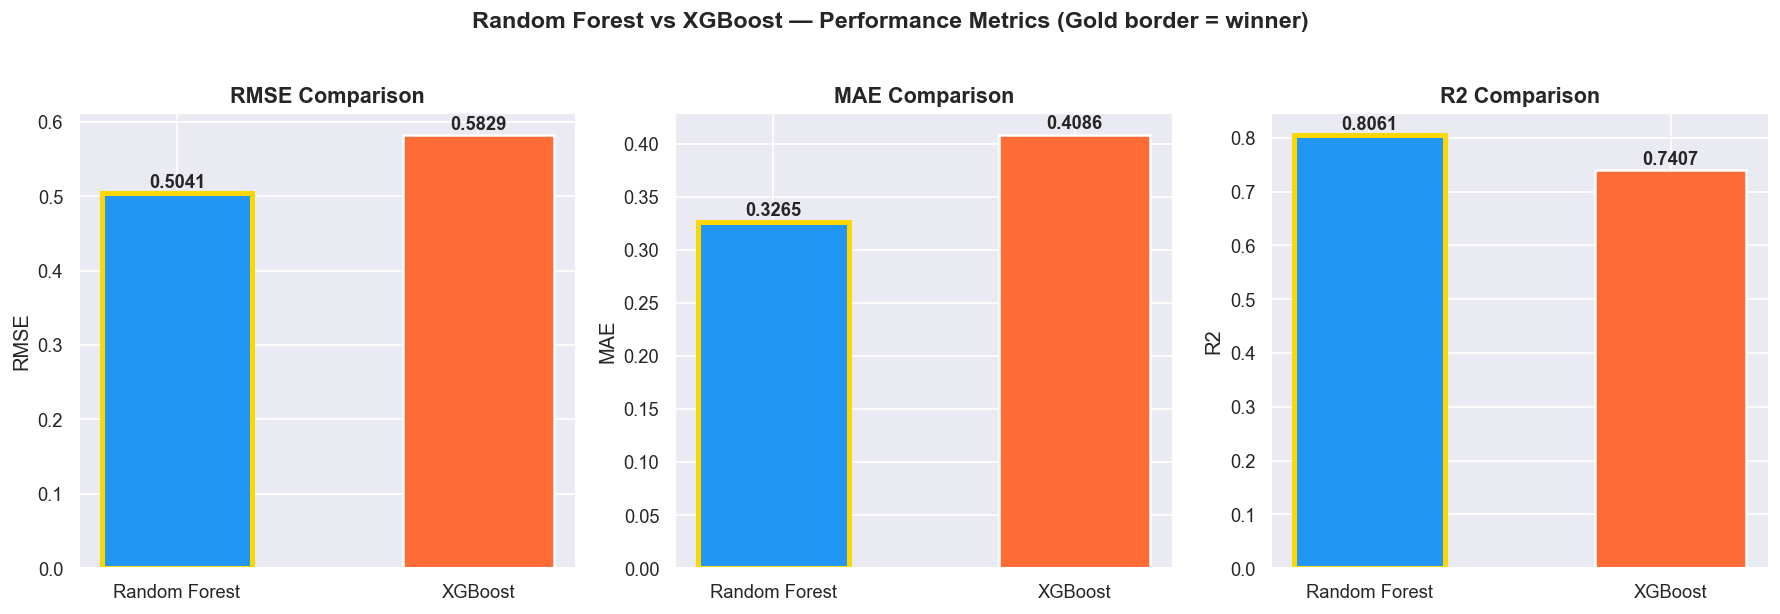

Saved: viz1_metrics_bar.png


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
colors  = ["#2196F3", "#FF6B35"]
models  = ["Random Forest", "XGBoost"]

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    values = [metrics.loc[m, metric] for m in models]
    bars = ax.bar(models, values, color=colors, width=0.5, edgecolor="white", linewidth=1.5)

    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.002,
                f"{val:.4f}", ha="center", va="bottom",
                fontweight="bold", fontsize=11)

    best = values.index(min(values)) if metric != "R2" else values.index(max(values))
    bars[best].set_edgecolor("gold")
    bars[best].set_linewidth(3)

    ax.set_title(f"{metric} Comparison", fontsize=13, fontweight="bold")
    ax.set_ylabel(metric)

plt.suptitle("Random Forest vs XGBoost — Performance Metrics (Gold border = winner)",
fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("viz1_metrics_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz1_metrics_bar.png")


## Cell 7 — Visualization 2: Actual vs Predicted

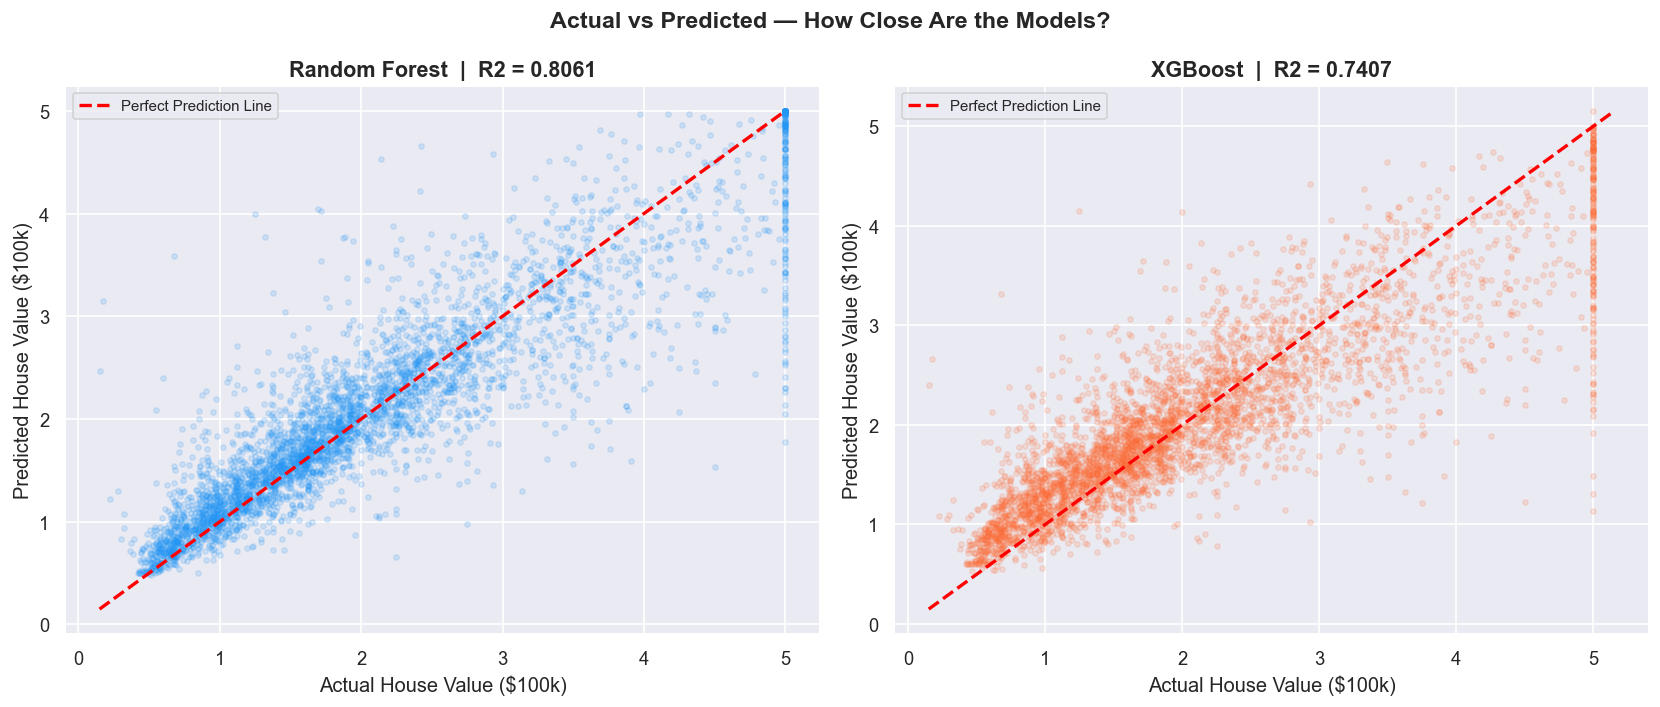

Saved: viz2_actual_vs_predicted.png


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, preds, name, color in zip(
    axes,
    [rf_preds, xgb_preds],
    ["Random Forest", "XGBoost"],
    ["#2196F3", "#FF6B35"]
):
    ax.scatter(y_test, preds, alpha=0.15, color=color, s=10)
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, "r--", lw=2, label="Perfect Prediction Line")
    r2 = r2_score(y_test, preds)
    ax.set_title(f"{name}  |  R2 = {r2:.4f}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Actual House Value ($100k)")
    ax.set_ylabel("Predicted House Value ($100k)")
    ax.legend(fontsize=9)

plt.suptitle("Actual vs Predicted — How Close Are the Models?",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("viz2_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz2_actual_vs_predicted.png")


## Cell 8 — Visualization 3: Residuals Analysis

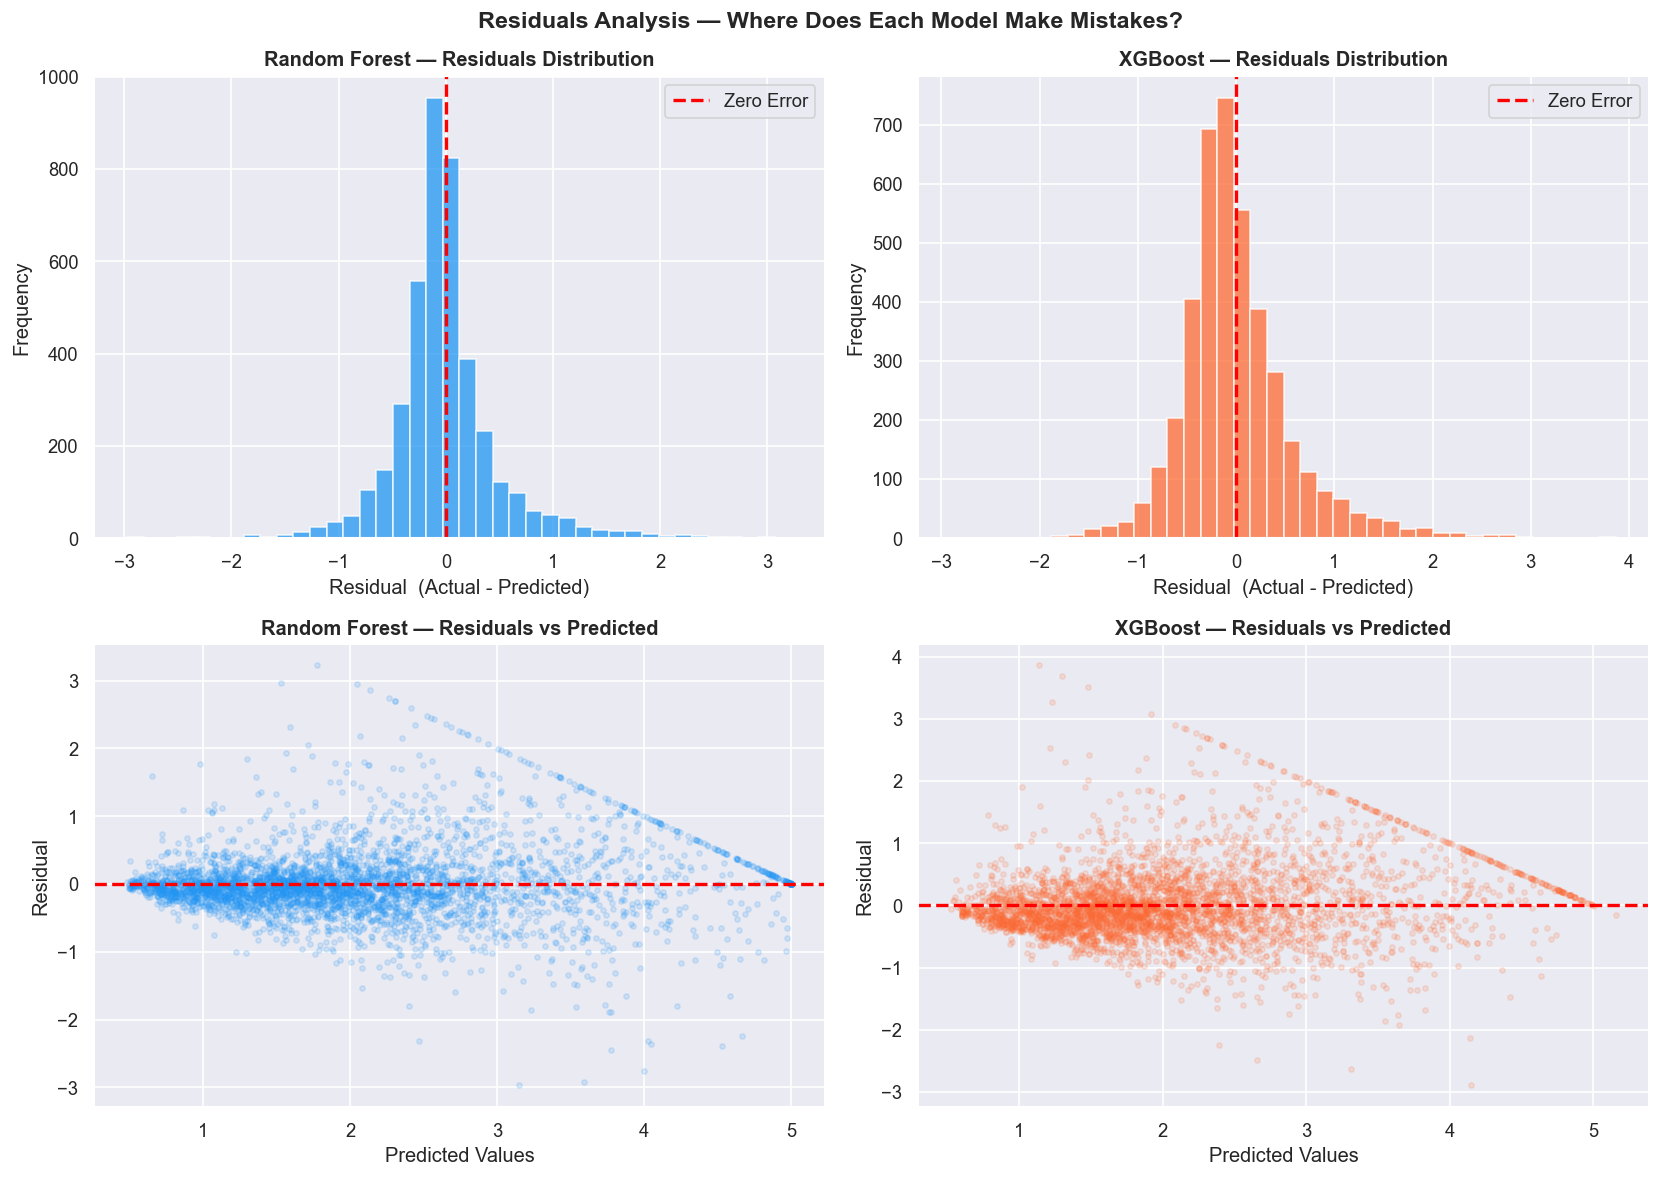

Saved: viz3_residuals.png


In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_data = [
    (rf_residuals,  rf_preds,  "Random Forest", "#2196F3"),
    (xgb_residuals, xgb_preds, "XGBoost",       "#FF6B35"),
]

for col, (residuals, preds, name, color) in enumerate(plot_data):

    # Row 1: Residuals distribution histogram
    axes[0, col].hist(residuals, bins=40, color=color, alpha=0.75, edgecolor="white")
    axes[0, col].axvline(0, color="red", linestyle="--", lw=2, label="Zero Error")
    axes[0, col].set_title(f"{name} — Residuals Distribution", fontweight="bold", fontsize=12)
    axes[0, col].set_xlabel("Residual  (Actual - Predicted)")
    axes[0, col].set_ylabel("Frequency")
    axes[0, col].legend()

    # Row 2: Residuals vs Predicted scatter
    axes[1, col].scatter(preds, residuals, alpha=0.15, color=color, s=10)
    axes[1, col].axhline(0, color="red", linestyle="--", lw=2)
    axes[1, col].set_title(f"{name} — Residuals vs Predicted", fontweight="bold", fontsize=12)
    axes[1, col].set_xlabel("Predicted Values")
    axes[1, col].set_ylabel("Residual")

plt.suptitle("Residuals Analysis — Where Does Each Model Make Mistakes?",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("viz3_residuals.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz3_residuals.png")


## Cell 9 — Visualization 4: Feature Importance Comparison

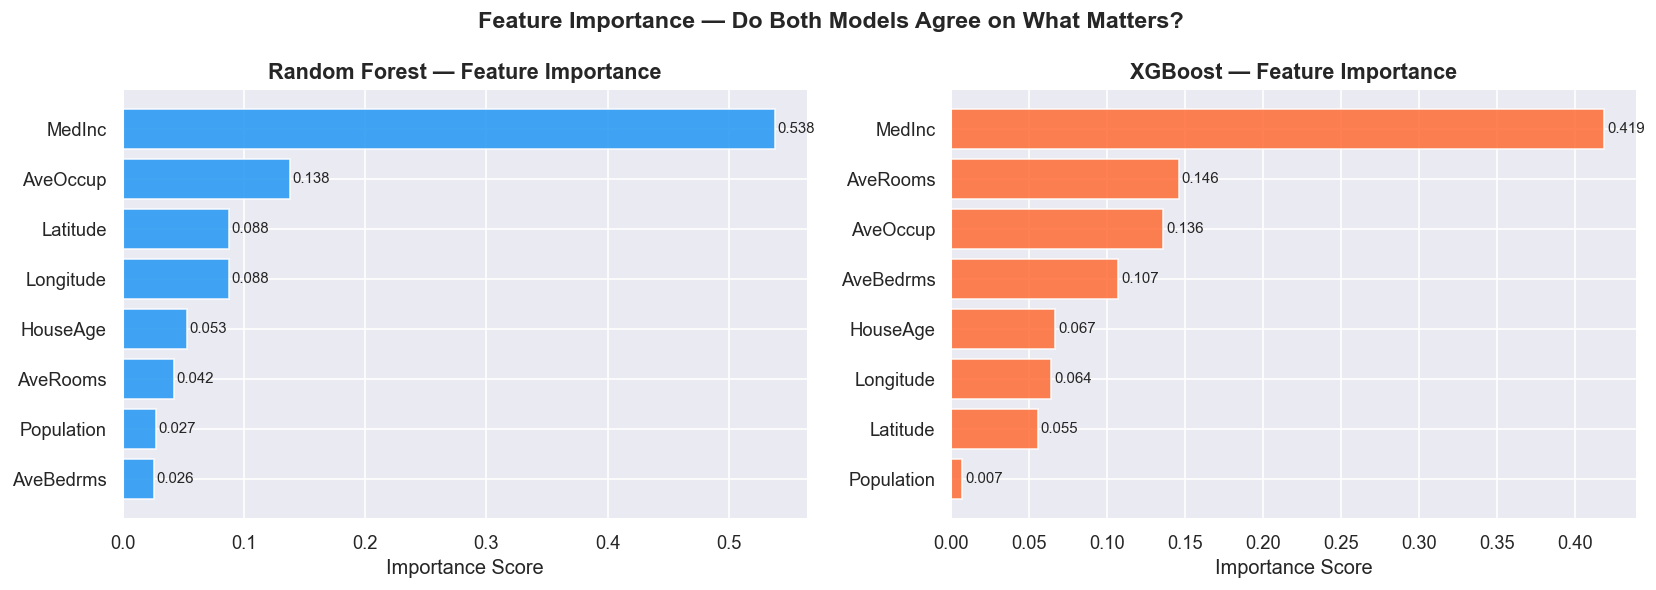

Top 3 features:
  Random Forest: ['MedInc', 'AveOccup', 'Latitude']
  XGBoost:       ['MedInc', 'AveRooms', 'AveOccup']
Saved: viz4_feature_importance.png


In [44]:
rf_imp  = pd.Series(rf_model.feature_importances_,  index=X_test.columns)
xgb_imp = pd.Series(xgb_model.feature_importances_, index=X_test.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, imp, name, color in zip(
    axes,
    [rf_imp, xgb_imp],
    ["Random Forest", "XGBoost"],
    ["#2196F3", "#FF6B35"]
):
    sorted_imp = imp.sort_values()
    bars = ax.barh(sorted_imp.index, sorted_imp.values, color=color, alpha=0.85)
    ax.set_title(f"{name} — Feature Importance", fontweight="bold", fontsize=13)
    ax.set_xlabel("Importance Score")

    # Annotate values
    for bar, val in zip(bars, sorted_imp.values):
        ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
                f"{val:.3f}", va="center", fontsize=9)

plt.suptitle("Feature Importance — Do Both Models Agree on What Matters?",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("viz4_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 3 features:")
print(f"  Random Forest: {list(rf_imp.sort_values(ascending=False).head(3).index)}")
print(f"  XGBoost:       {list(xgb_imp.sort_values(ascending=False).head(3).index)}")
print("Saved: viz4_feature_importance.png")


## Cell 10 — Visualization 5: Error Distribution Overlay

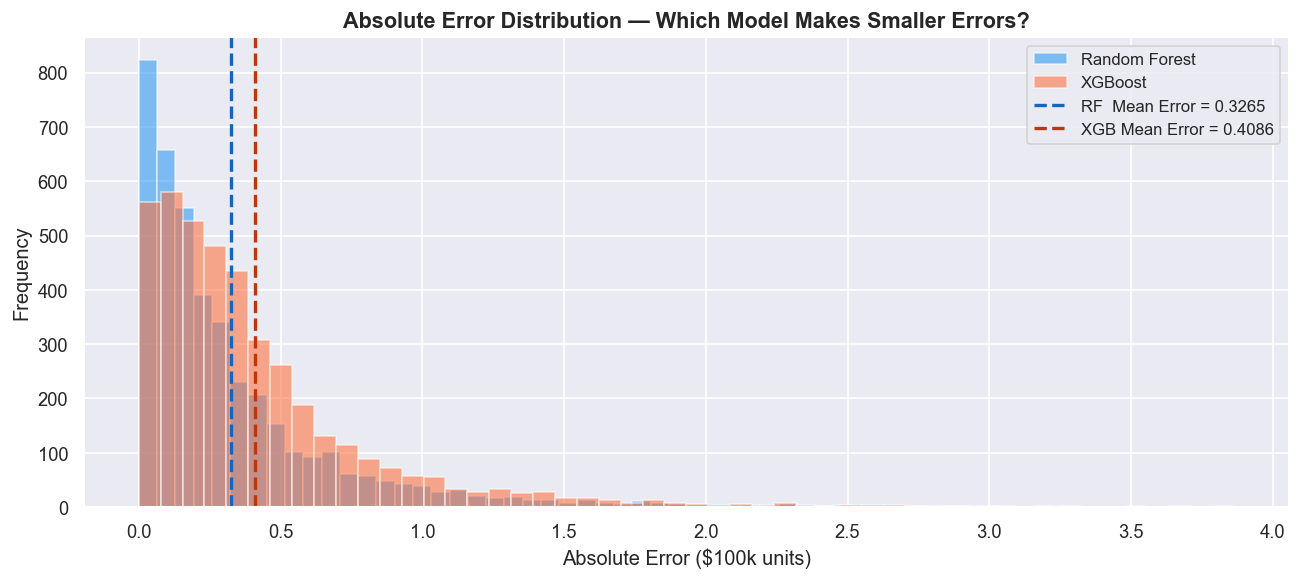

Saved: viz5_error_overlay.png


In [45]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(np.abs(rf_residuals),  bins=50, alpha=0.55, color="#2196F3", label="Random Forest")
ax.hist(np.abs(xgb_residuals), bins=50, alpha=0.55, color="#FF6B35", label="XGBoost")

rf_mean  = np.mean(np.abs(rf_residuals))
xgb_mean = np.mean(np.abs(xgb_residuals))

ax.axvline(rf_mean,  color="#1565C0", linestyle="--", lw=2, label=f"RF  Mean Error = {rf_mean:.4f}")
ax.axvline(xgb_mean, color="#BF360C", linestyle="--", lw=2, label=f"XGB Mean Error = {xgb_mean:.4f}")

ax.set_title("Absolute Error Distribution — Which Model Makes Smaller Errors?",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Absolute Error ($100k units)")
ax.set_ylabel("Frequency")
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("viz5_error_overlay.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: viz5_error_overlay.png")


## Cell 11 — Final Verdict

In [46]:
rf_r2   = metrics.loc["Random Forest", "R2"]
xgb_r2  = metrics.loc["XGBoost",       "R2"]
rf_rmse = metrics.loc["Random Forest", "RMSE"]
xgb_rmse= metrics.loc["XGBoost",       "RMSE"]
rf_mae  = metrics.loc["Random Forest", "MAE"]
xgb_mae = metrics.loc["XGBoost",       "MAE"]

winner = "Random Forest" if rf_r2 > xgb_r2 else "XGBoost"
loser  = "XGBoost" if winner == "Random Forest" else "Random Forest"

print("=" * 60)
print("            FINAL EVALUATION VERDICT")
print("=" * 60)
print()
print(metrics.to_string())
print()
print(f"  WINNER:  {winner}")
print()
print("  Reasons:")
print(f"   R2   -> {winner} explains more variance in house prices")
print(f"   RMSE -> {metrics['RMSE'].idxmin()} has lower error on large mistakes")
print(f"   MAE  -> {metrics['MAE'].idxmin()} is more accurate on average predictions")
print()
print("  Key Observations:")
print("   Both models agree: MedInc is the #1 driver of house prices")
print("   The $500k data cap hurts both models equally at the top range")
print("   Both models perform well below $300k (middle-income market)")
print()
print(f"  Recommendation: Use {winner} for production deployment")
print("=" * 60)


            FINAL EVALUATION VERDICT

                 RMSE     MAE      R2
Model                                
Random Forest  0.5041  0.3265  0.8061
XGBoost        0.5829  0.4086  0.7407

  WINNER:  Random Forest

  Reasons:
   R2   -> Random Forest explains more variance in house prices
   RMSE -> Random Forest has lower error on large mistakes
   MAE  -> Random Forest is more accurate on average predictions

  Key Observations:
   Both models agree: MedInc is the #1 driver of house prices
   The $500k data cap hurts both models equally at the top range
   Both models perform well below $300k (middle-income market)

  Recommendation: Use Random Forest for production deployment
